# STGAN - Tăng cường dữ liệu bằng GAN cho phân loại tổn thương da (HAM10000)

Cài đặt lại bài "A GAN-Based Data Augmentation Method for Imbalanced Multi-Class Skin Lesion Classification" (Su et al., IEEE Access 2024).

## Vì sao phải chạy nhiều lần?

Toàn bộ pipeline (stage 1 + stage 2 cho 7 lớp + 3 bộ phân loại) dài hơn 12 giờ (giới hạn mỗi phiên Kaggle). Notebook tự lưu checkpoint trước khi hết giờ và tự train tiếp ở lần chạy sau.

Kết quả nằm trong tab Output: `runs/stgan/...` (checkpoint, ảnh mẫu, log), `runs/gan_eval.csv`, `runs/cls_*/metrics.json`, ma trận nhầm lẫn.

In [ ]:
# ======================= CẤU HÌNH =======================
import time
T0 = time.time()

QUICK_TEST = False        # True = chạy thử nhanh (ảnh 64px, vài trăm vòng lặp) để kiểm tra lỗi
MAX_HOURS = 11.3          # Kaggle dừng ở 12 giờ -> chừa thời gian lưu kết quả

RES = 256                 # độ phân giải GAN (bài báo: 256)
STAGE1_ITERS = 40000      # số vòng lặp stage 1 (toàn bộ dữ liệu)
STAGE2_ITERS = 8000       # số vòng lặp stage 2 (mỗi lớp); giữ 8000 vì akiec, bcc đã train 8000 vòng
GAN_BATCH = 32            # giảm xuống 16 nếu báo hết bộ nhớ GPU
LAMBDA_SS = 0.01          # trọng số Barlow Twins
FREEZE_D = 2              # số block D bị đóng băng ở stage 2
CLS_EPOCHS = 50           # số epoch bộ phân loại
CLS_BATCH = 128           # giảm xuống 64 nếu hết bộ nhớ GPU
GROUP_BY_LESION = False   # True = chia train/test theo lesion_id (tránh rò rỉ dữ liệu, điểm bài báo không làm)
SPLIT_CSV = None          # vd "HAM10000_lesion_split_seed42_v2.csv" để dùng file chia sẵn
SYNTH_COUNTS = {"akiec": 3000, "bcc": 3000, "bkl": 3000, "df": 3000, "mel": 3000, "nv": 500, "vasc": 3000}

# Thí nghiệm phân loại (Table 3). Chạy theo thứ tự này. Cái nào xong rồi sẽ được bỏ qua.
# Số giờ ước lượng dùng để quyết định có đủ thời gian bắt đầu trong phiên hiện tại hay không.
EXPERIMENTS = [
    # (tên,              tham số thêm,              dùng ảnh STGAN?, giờ ước lượng)
    ("tresnet50_stgan", [],                         True,  3.0),
    ("tresnet50",       [],                         False, 1.2),
    ("resnet50",        ["--arch", "resnet50"],     False, 1.2),
]

if QUICK_TEST:
    RES, STAGE1_ITERS, STAGE2_ITERS, CLS_EPOCHS = 64, 300, 100, 1
    SYNTH_COUNTS = {c: 50 for c in SYNTH_COUNTS}
    EXPERIMENTS = [(n, a, s, 0.1) for n, a, s, _ in EXPERIMENTS]

In [ ]:
import os, sys, glob, json, shutil, subprocess
from pathlib import Path

WORK = Path("/kaggle/working")
CODE = WORK / "code"
RUNS = WORK / ("runs_quick" if QUICK_TEST else "runs")
DATA = Path("/tmp/data_" + (Path(SPLIT_CSV).stem if SPLIT_CSV else "lesion" if GROUP_BY_LESION else "random"))  # không lưu vào output
SYN = Path("/tmp/synth_quick" if QUICK_TEST else "/tmp/synth")
CODE.mkdir(parents=True, exist_ok=True)
RUNS.mkdir(parents=True, exist_ok=True)
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
DEADLINE = T0 + MAX_HOURS * 3600


def hours_left():
    return (DEADLINE - time.time()) / 3600


import threading, queue
import torch
N_GPU = max(1, torch.cuda.device_count())
_print_lock = threading.Lock()


def run(args, gpu=None, prefix=""):
    # Chạy 1 script trong thư mục code (trên GPU số `gpu` nếu có), in log trực tiếp
    cmd = [sys.executable, "-u"] + [str(a) for a in args]
    env = dict(os.environ, TQDM_DISABLE="1", PYTHONUNBUFFERED="1")
    if gpu is not None:
        env["CUDA_VISIBLE_DEVICES"] = str(gpu)
    with _print_lock:
        print(prefix + "$", " ".join(cmd[2:]), flush=True)
    p = subprocess.Popen(cmd, cwd=CODE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        with _print_lock:
            print(prefix + line, end="", flush=True)
    if p.wait() != 0:
        raise RuntimeError(f"Lệnh lỗi (exit {p.returncode}): {' '.join(cmd[2:])}")


def run_parallel(jobs):
    # jobs: list (tên, args, số giờ ước lượng). Mỗi GPU lần lượt nhận job tiếp theo trong hàng đợi,
    # job chỉ được bắt đầu nếu còn đủ thời gian trong phiên.
    q = queue.Queue()
    for j in jobs:
        q.put(j)
    errors = []

    def worker(gpu):
        while True:
            try:
                name, args, est = q.get_nowait()
            except queue.Empty:
                return
            if hours_left() < est:
                with _print_lock:
                    print(f"[GPU{gpu}] Còn {hours_left():.1f} giờ, không đủ cho {name} (~{est} giờ) -> để lần chạy sau")
                continue
            try:
                run(args, gpu=gpu, prefix=f"[GPU{gpu}] ")
            except RuntimeError as e:
                errors.append(f"{name}: {e}")
                with _print_lock:
                    print(f"[GPU{gpu}] LỖI {name}: {e}")

    threads = [threading.Thread(target=worker, args=(g,)) for g in range(N_GPU)]
    for t in threads:
        t.start()
    for t in threads:
        t.join()
    return errors


def find(name, root="/kaggle/input"):
    # Tìm file/thư mục (vd HAM10000_metadata.csv hoặc runs/stgan) ở mọi độ sâu, nông nhất trước
    hits = []
    for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
        cand = os.path.join(dirpath, name)
        if os.path.exists(cand):
            hits.append(cand)
        if len(filenames) > 500:          # thư mục ảnh -> không cần đi sâu thêm
            dirnames[:] = []
    return sorted(hits, key=lambda h: (h.count(os.sep), h))


def show_tree(root="/kaggle/input", depth=4):
    for dirpath, dirnames, filenames in os.walk(root, followlinks=True):
        lvl = dirpath[len(root):].count(os.sep)
        print("  " * lvl + os.path.basename(dirpath) + f"/  ({len(filenames)} file)")
        if lvl >= depth or len(filenames) > 500:
            dirnames[:] = []

## Mã nguồn (ghi ra thư mục `code/`)

In [3]:
%%writefile /kaggle/working/code/common.py
"""Tiện ích dùng chung: danh sách lớp, dataset, seed."""
import random
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset

# Thứ tự lớp theo alphabet (giống nhãn 'dx' trong HAM10000_metadata.csv)
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def seed_everything(seed: int = 0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def list_class_images(root, cls):
    d = Path(root) / cls
    if not d.exists():
        return []
    return sorted(p for p in d.iterdir() if p.suffix.lower() in IMG_EXTS)


def list_labeled_images(root, classes=CLASSES):
    """Trả về list (path, label) cho cấu trúc root/<class>/*.jpg"""
    items = []
    for c in classes:
        label = CLASSES.index(c)
        items += [(p, label) for p in list_class_images(root, c)]
    return items


class ImageDataset(Dataset):
    def __init__(self, items, transform=None):
        self.items = list(items)
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        p, y = self.items[i]
        img = Image.open(p).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, y


def infinite_loader(loader):
    while True:
        for batch in loader:
            yield batch


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

Writing /kaggle/working/code/common.py


In [ ]:
%%writefile /kaggle/working/code/diffaug.py
"""Augmentation khả vi (differentiable) cho cả ảnh thật và ảnh giả khi train D.

Thay thế cho ADA của StyleGAN2-ADA (bài báo dùng ADA). Đồng thời dùng để tạo
2 "view" khác nhau cho Barlow Twins ở stage 2.
Ảnh đầu vào ở khoảng [-1, 1], shape [B, C, H, W], H == W.
"""
import torch
import torch.nn.functional as F


def rand_brightness(x):
    return x + (torch.rand(x.size(0), 1, 1, 1, device=x.device) - 0.5)


def rand_saturation(x):
    mean = x.mean(dim=1, keepdim=True)
    return (x - mean) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) * 2) + mean


def rand_contrast(x):
    mean = x.mean(dim=[1, 2, 3], keepdim=True)
    return (x - mean) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) + 0.5) + mean


def rand_translation(x, ratio=0.125):
    B, _, H, W = x.shape
    sh, sw = int(H * ratio + 0.5), int(W * ratio + 0.5)
    tx = torch.randint(-sh, sh + 1, (B, 1, 1), device=x.device)
    ty = torch.randint(-sw, sw + 1, (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device), torch.arange(H, device=x.device),
                                torch.arange(W, device=x.device), indexing="ij")
    gx = torch.clamp(gx + tx + 1, 0, H + 1)
    gy = torch.clamp(gy + ty + 1, 0, W + 1)
    x_pad = F.pad(x, [1, 1, 1, 1])
    return x_pad.permute(0, 2, 3, 1).contiguous()[gb, gx, gy].permute(0, 3, 1, 2).contiguous()


def rand_cutout(x, ratio=0.5):
    B, _, H, W = x.shape
    ch, cw = int(H * ratio + 0.5), int(W * ratio + 0.5)
    ox = torch.randint(0, H + (1 - ch % 2), (B, 1, 1), device=x.device)
    oy = torch.randint(0, W + (1 - cw % 2), (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device), torch.arange(ch, device=x.device),
                                torch.arange(cw, device=x.device), indexing="ij")
    gx = torch.clamp(gx + ox - ch // 2, 0, H - 1)
    gy = torch.clamp(gy + oy - cw // 2, 0, W - 1)
    mask = torch.ones(B, H, W, dtype=x.dtype, device=x.device)
    mask[gb, gx, gy] = 0
    return x * mask.unsqueeze(1)


def rand_fliprot(x):
    """Lật ngang + xoay 90° ngẫu nhiên cho từng ảnh (ảnh soi da không có hướng cố định)."""
    B = x.size(0)
    flip = torch.rand(B, 1, 1, 1, device=x.device) < 0.5
    x = torch.where(flip, x.flip(3), x)
    k = torch.randint(0, 4, (B,), device=x.device)
    rots = torch.stack([torch.rot90(x, r, dims=(2, 3)) for r in range(4)])  # [4, B, C, H, W]
    return rots[k, torch.arange(B, device=x.device)]


_POLICIES = {
    "color": [rand_brightness, rand_saturation, rand_contrast],
    "translation": [rand_translation],
    "cutout": [rand_cutout],
    "fliprot": [rand_fliprot],
}


def DiffAugment(x, policy="color,translation,cutout,fliprot"):
    if not policy:
        return x
    for p in policy.split(","):
        for fn in _POLICIES[p.strip()]:
            x = fn(x)
    return x

Writing /kaggle/working/code/diffaug.py


In [5]:
%%writefile /kaggle/working/code/models_gan.py
"""Generator / Discriminator dạng ResNet + Barlow Twins loss + Freeze-D.

Ghi chú: bài báo dùng StyleGAN2 (+ADA) làm backbone. Ở đây dùng ResNet-GAN
(G: BatchNorm, D: Spectral Norm) gọn hơn, dễ train trên 1 GPU. Ý tưởng STGAN
(2 stage, Barlow Twins trong D, Freeze-D) giữ nguyên.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.parametrizations import spectral_norm as SN

G_MULTS = {64: [16, 8, 4, 2, 1], 128: [16, 16, 8, 4, 2, 1], 256: [16, 16, 8, 8, 4, 2, 1]}
D_MULTS = {64: [1, 2, 4, 8, 16], 128: [1, 2, 4, 8, 16, 16], 256: [1, 2, 4, 8, 8, 16, 16]}


# ----------------------------- Generator -----------------------------
class GBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(cin)
        self.conv1 = nn.Conv2d(cin, cout, 3, 1, 1)
        self.bn2 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1)
        self.sc = nn.Conv2d(cin, cout, 1)

    def forward(self, x):
        h = F.interpolate(F.relu(self.bn1(x)), scale_factor=2, mode="nearest")
        h = self.conv2(F.relu(self.bn2(self.conv1(h))))
        return h + self.sc(F.interpolate(x, scale_factor=2, mode="nearest"))


class Generator(nn.Module):
    def __init__(self, z_dim=128, ch=32, res=256):
        super().__init__()
        m = G_MULTS[res]
        self.z_dim, self.c0 = z_dim, ch * m[0]
        self.fc = nn.Linear(z_dim, 4 * 4 * self.c0)
        self.blocks = nn.ModuleList([GBlock(ch * m[i], ch * m[i + 1]) for i in range(len(m) - 1)])
        self.out = nn.Sequential(nn.BatchNorm2d(ch * m[-1]), nn.ReLU(True),
                                 nn.Conv2d(ch * m[-1], 3, 3, 1, 1), nn.Tanh())

    def forward(self, z):
        h = self.fc(z).view(z.size(0), self.c0, 4, 4)
        for b in self.blocks:
            h = b(h)
        return self.out(h)


# --------------------------- Discriminator ---------------------------
class DBlock(nn.Module):
    def __init__(self, cin, cout, down=True, preact=True):
        super().__init__()
        self.conv1 = SN(nn.Conv2d(cin, cout, 3, 1, 1))
        self.conv2 = SN(nn.Conv2d(cout, cout, 3, 1, 1))
        self.sc = SN(nn.Conv2d(cin, cout, 1)) if (cin != cout or down) else None
        self.down, self.preact = down, preact

    def forward(self, x):
        h = F.relu(x) if self.preact else x
        h = self.conv2(F.relu(self.conv1(h)))
        if self.down:
            h = F.avg_pool2d(h, 2)
        s = x
        if self.sc is not None:
            if self.preact:
                s = self.sc(s)
                s = F.avg_pool2d(s, 2) if self.down else s
            else:
                s = F.avg_pool2d(s, 2) if self.down else s
                s = self.sc(s)
        return h + s


class Discriminator(nn.Module):
    """blocks[0] là block độ phân giải cao nhất (gần input) -> Freeze-D đóng băng từ đây."""

    def __init__(self, ch=32, res=256):
        super().__init__()
        m = D_MULTS[res]
        blocks = [DBlock(3, ch * m[0], down=True, preact=False)]
        for i in range(1, len(m) - 1):
            blocks.append(DBlock(ch * m[i - 1], ch * m[i], down=True))
        blocks.append(DBlock(ch * m[-2], ch * m[-1], down=False))
        self.blocks = nn.ModuleList(blocks)
        self.feat_dim = ch * m[-1]
        self.fc = SN(nn.Linear(self.feat_dim, 1))

    def forward(self, x, return_feat=False):
        h = x
        for b in self.blocks:
            h = b(h)
        feat = F.relu(h).sum(dim=[2, 3])  # đặc trưng lớp áp chót -> dùng cho Barlow Twins
        logit = self.fc(feat).squeeze(1)
        return (logit, feat) if return_feat else logit


def freeze_d(D: Discriminator, n: int):
    """Freeze-D: đóng băng n block có độ phân giải cao nhất của D."""
    for b in D.blocks[:n]:
        b.requires_grad_(False)


# ---------------------------- Barlow Twins ----------------------------
def barlow_twins_loss(ya, yb, lambd=5e-3, eps=1e-8):
    """Eq.(4)-(5) trong bài báo. ya, yb: [N, D] đặc trưng của 2 view."""
    ya = ya - ya.mean(0)
    yb = yb - yb.mean(0)
    ya = ya / (ya.norm(dim=0, keepdim=True) + eps)
    yb = yb / (yb.norm(dim=0, keepdim=True) + eps)
    c = ya.T @ yb  # ma trận cross-correlation [D, D]
    diag = torch.diagonal(c)
    on_diag = (1 - diag).pow(2).sum()
    off_diag = c.pow(2).sum() - diag.pow(2).sum()
    return on_diag + lambd * off_diag

Writing /kaggle/working/code/models_gan.py


In [ ]:
%%writefile /kaggle/working/code/train_stgan.py
"""Huấn luyện STGAN (Self-Transfer GAN) 2 giai đoạn.

Stage 1: GAN không điều kiện trên TOÀN BỘ ảnh train -> học tri thức chung.
  python train_stgan.py --stage 1 --data data/train --out runs/stgan --iters 40000

Stage 2: khởi tạo từ stage 1, fine-tune RIÊNG từng lớp, D có thêm
         Barlow Twins (self-supervised) + Freeze-D.
  python train_stgan.py --stage 2 --data data/train --out runs/stgan \
      --stage1-ckpt runs/stgan/stage1/final.pt --iters 8000

Loss D stage 2:  L = L_gan + lambda_ss * L_ss   (Eq. 6)

Tự động train tiếp (resume): nếu thư mục đã có last.pt thì train tiếp từ đó,
nếu đã có final.pt thì bỏ qua. --max-hours / --deadline: dừng an toàn và lưu
last.pt trước khi hết giờ (hữu ích trên Kaggle/Colab giới hạn 12 giờ).
"""
import argparse
import csv
import time
from pathlib import Path

import torch
import torch.nn.functional as F
import torchvision.transforms as T
from torch.utils.data import DataLoader
from torchvision.utils import save_image

from common import (CLASSES, ImageDataset, get_device, infinite_loader, list_class_images,
                    list_labeled_images, seed_everything)
from diffaug import DiffAugment
from models_gan import Discriminator, Generator, barlow_twins_loss, freeze_d

ARCH_KEYS = ["res", "z_dim", "g_ch", "d_ch"]


def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--stage", type=int, choices=[1, 2], required=True)
    p.add_argument("--data", default="data/train")
    p.add_argument("--out", default="runs/stgan")
    # kiến trúc
    p.add_argument("--res", type=int, default=256, choices=[64, 128, 256])
    p.add_argument("--z-dim", type=int, default=128)
    p.add_argument("--g-ch", type=int, default=32)
    p.add_argument("--d-ch", type=int, default=32)
    # huấn luyện
    p.add_argument("--batch", type=int, default=32)
    p.add_argument("--iters", type=int, default=None, help="mặc định: 40000 (stage 1), 8000 (stage 2)")
    p.add_argument("--lr-g", type=float, default=2e-4)
    p.add_argument("--lr-d", type=float, default=2e-4)
    p.add_argument("--r1-gamma", type=float, default=0.5, help="R1 regularization (0 để tắt)")
    p.add_argument("--r1-every", type=int, default=16, help="lazy R1")
    p.add_argument("--ema-kimg", type=float, default=10.0, help="half-life EMA của G (nghìn ảnh)")
    p.add_argument("--policy", default="color,translation,cutout,fliprot", help="DiffAugment")
    # stage 2
    p.add_argument("--stage1-ckpt", default=None)
    p.add_argument("--classes", nargs="+", default=CLASSES)
    p.add_argument("--freeze-d", type=int, default=2, help="số block độ phân giải cao của D bị đóng băng")
    p.add_argument("--lambda-ss", type=float, default=0.01, help="trọng số Barlow Twins (lambda_ss)")
    p.add_argument("--bt-lambda", type=float, default=5e-3, help="lambda off-diagonal trong Barlow Twins")
    p.add_argument("--no-bt", action="store_true", help="tắt Barlow Twins (ablation)")
    # khác
    p.add_argument("--log-every", type=int, default=100)
    p.add_argument("--sample-every", type=int, default=1000)
    p.add_argument("--ckpt-every", type=int, default=2000,
                   help="lưu ckpt_xxxxxx.pt (chỉ G_ema, nhẹ) + last.pt (đầy đủ, để resume)")
    p.add_argument("--workers", type=int, default=4)
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--max-hours", type=float, default=None, help="dừng an toàn sau số giờ này")
    p.add_argument("--deadline", type=float, default=None, help="dừng an toàn tại unix timestamp này")
    a = p.parse_args()
    if a.iters is None:
        a.iters = 40000 if a.stage == 1 else 8000
    if a.max_hours is not None:
        dl = time.time() + a.max_hours * 3600
        a.deadline = dl if a.deadline is None else min(a.deadline, dl)
    return a


def gan_transform(res):
    return T.Compose([T.Resize(res), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.ToTensor(), T.Normalize([0.5] * 3, [0.5] * 3)])


def build_models(args, device):
    G = Generator(args.z_dim, args.g_ch, args.res).to(device)
    D = Discriminator(args.d_ch, args.res).to(device)
    G_ema = Generator(args.z_dim, args.g_ch, args.res).to(device)
    G_ema.load_state_dict(G.state_dict())
    G_ema.eval().requires_grad_(False)
    return G, D, G_ema


@torch.no_grad()
def update_ema(G_ema, G, beta):
    for pe, p in zip(G_ema.parameters(), G.parameters()):
        pe.lerp_(p, 1 - beta)
    for be, b in zip(G_ema.buffers(), G.buffers()):
        be.copy_(b)


def set_requires_grad(params, flag):
    for p in params:
        p.requires_grad_(flag)


def save_full(path, G, D, G_ema, optG, optD, step, args):
    tmp = Path(str(path) + ".tmp")
    torch.save({"G": G.state_dict(), "D": D.state_dict(), "G_ema": G_ema.state_dict(),
                "optG": optG.state_dict(), "optD": optD.state_dict(),
                "step": step, "args": vars(args)}, tmp)
    tmp.replace(path)  # ghi nguyên tử, tránh file hỏng nếu bị ngắt giữa chừng


def save_light(path, G_ema, step, args):
    """Checkpoint nhẹ (chỉ G_ema) để sinh ảnh / chọn checkpoint tốt nhất."""
    torch.save({"G_ema": G_ema.state_dict(), "step": step, "args": vars(args)}, path)


def train(args, G, D, G_ema, loader, out_dir, use_bt, device):
    """Trả về True nếu train xong, False nếu dừng vì hết giờ (đã lưu last.pt)."""
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / "samples").mkdir(exist_ok=True)
    d_params = [p for p in D.parameters() if p.requires_grad]  # không gồm các layer bị Freeze-D
    optG = torch.optim.Adam(G.parameters(), lr=args.lr_g, betas=(0.0, 0.99))
    optD = torch.optim.Adam(d_params, lr=args.lr_d, betas=(0.0, 0.99))

    start_step = 0
    last = out_dir / "last.pt"
    if last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)
        G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"]); G_ema.load_state_dict(ck["G_ema"])
        optG.load_state_dict(ck["optG"]); optD.load_state_dict(ck["optD"])
        start_step = ck["step"]
        print(f"[{out_dir.name}] Train tiếp từ vòng {start_step}")
        del ck

    batch = loader.batch_size
    ema_beta = 0.5 ** (batch / (args.ema_kimg * 1000))
    data = infinite_loader(loader)
    fixed_z = torch.randn(64, args.z_dim, generator=torch.Generator().manual_seed(123)).to(device)

    log_f = open(out_dir / "log.csv", "a", newline="")
    logger = csv.writer(log_f)
    if start_step == 0:
        logger.writerow(["step", "loss_D", "loss_G", "loss_ss", "loss_r1", "D_real", "D_fake"])

    t0 = time.time()
    loss_r1 = torch.zeros((), device=device)
    for step in range(start_step + 1, args.iters + 1):
        real, _ = next(data)
        real = real.to(device, non_blocking=True)
        B = real.size(0)

        # ------------------ cập nhật D ------------------
        set_requires_grad(d_params, True)
        with torch.no_grad():
            fake = G(torch.randn(B, args.z_dim, device=device))
        x = torch.cat([real, fake])                      # X = [X_r ; X_g]
        logits, feat_a = D(DiffAugment(x, args.policy), return_feat=True)   # view a
        loss_adv = F.softplus(-logits[:B]).mean() + F.softplus(logits[B:]).mean()
        loss_ss = torch.zeros((), device=device)
        if use_bt:
            _, feat_b = D(DiffAugment(x, args.policy), return_feat=True)    # view b
            loss_ss = barlow_twins_loss(feat_a, feat_b, args.bt_lambda)
        loss_D = loss_adv + args.lambda_ss * loss_ss
        optD.zero_grad(set_to_none=True)
        loss_D.backward()
        optD.step()

        # lazy R1 regularization (như StyleGAN2)
        if args.r1_gamma > 0 and step % args.r1_every == 0:
            real_r = real.detach().requires_grad_(True)
            out = D(DiffAugment(real_r, args.policy))
            grad, = torch.autograd.grad(out.sum(), real_r, create_graph=True)
            loss_r1 = grad.pow(2).flatten(1).sum(1).mean() * (args.r1_gamma * 0.5 * args.r1_every)
            optD.zero_grad(set_to_none=True)
            loss_r1.backward()
            optD.step()

        # ------------------ cập nhật G ------------------
        set_requires_grad(d_params, False)
        fake = G(torch.randn(B, args.z_dim, device=device))
        loss_G = F.softplus(-D(DiffAugment(fake, args.policy))).mean()
        optG.zero_grad(set_to_none=True)
        loss_G.backward()
        optG.step()
        update_ema(G_ema, G, ema_beta)

        # ------------------ log / lưu ------------------
        if step % args.log_every == 0:
            d_real, d_fake = logits[:B].mean().item(), logits[B:].mean().item()
            logger.writerow([step, f"{loss_D.item():.4f}", f"{loss_G.item():.4f}", f"{loss_ss.item():.4f}",
                             f"{loss_r1.item():.4f}", f"{d_real:.4f}", f"{d_fake:.4f}"])
            log_f.flush()
            el = time.time() - t0
            eta = el / (step - start_step) * (args.iters - step) / 60
            print(f"[{out_dir.name}] it {step}/{args.iters} | D {loss_D.item():.3f} G {loss_G.item():.3f} "
                  f"ss {loss_ss.item():.3f} r1 {loss_r1.item():.3f} | D(real) {d_real:.2f} "
                  f"D(fake) {d_fake:.2f} | {el / 60:.0f} phút, còn ~{eta:.0f} phút", flush=True)
        if step % args.sample_every == 0 or step == args.iters:
            with torch.no_grad():
                save_image(G_ema(fixed_z) * 0.5 + 0.5, out_dir / "samples" / f"{step:06d}.png", nrow=8)
        if step % args.ckpt_every == 0:
            save_light(out_dir / f"ckpt_{step:06d}.pt", G_ema, step, args)
            if step < args.iters:
                save_full(last, G, D, G_ema, optG, optD, step, args)
        if args.deadline is not None and time.time() > args.deadline and step < args.iters:
            save_full(last, G, D, G_ema, optG, optD, step, args)
            print(f"[{out_dir.name}] Hết thời gian -> đã lưu last.pt ở vòng {step}. Chạy lại để train tiếp.")
            log_f.close()
            return False
    save_full(out_dir / "final.pt", G, D, G_ema, optG, optD, args.iters, args)
    last.unlink(missing_ok=True)
    log_f.close()
    return True


def make_loader(items, args):
    ds = ImageDataset(items, gan_transform(args.res))
    bs = min(args.batch, len(ds))
    return DataLoader(ds, batch_size=bs, shuffle=True, num_workers=args.workers, drop_last=True,
                      pin_memory=torch.cuda.is_available(), persistent_workers=args.workers > 0)


def main():
    args = parse_args()
    seed_everything(args.seed)
    device = get_device()
    out = Path(args.out)

    if args.stage == 1:
        cls_dir = out / "stage1"
        if (cls_dir / "final.pt").exists():
            print("Stage 1 đã xong (có final.pt), bỏ qua.")
            return
        last = cls_dir / "last.pt"
        if last.exists():  # kiến trúc lấy theo checkpoint đang dở
            ck = torch.load(last, map_location="cpu", weights_only=False)
            for k in ARCH_KEYS:
                setattr(args, k, ck["args"][k])
            del ck
        items = list_labeled_images(args.data)
        print(f"Stage 1: {len(items)} ảnh train (tất cả các lớp)")
        G, D, G_ema = build_models(args, device)
        train(args, G, D, G_ema, make_loader(items, args), cls_dir, use_bt=False, device=device)

    else:
        assert args.stage1_ckpt, "Cần --stage1-ckpt cho stage 2"
        ck = torch.load(args.stage1_ckpt, map_location="cpu", weights_only=False)
        for k in ARCH_KEYS:  # kiến trúc phải khớp với stage 1
            setattr(args, k, ck["args"][k])
        for cls in args.classes:
            cls_dir = out / "stage2" / cls
            if (cls_dir / "final.pt").exists():
                print(f"Bỏ qua {cls}: đã có final.pt")
                continue
            if args.deadline is not None and time.time() > args.deadline:
                print("Hết thời gian, dừng stage 2. Chạy lại để train các lớp còn lại.")
                break
            items = [(p, CLASSES.index(cls)) for p in list_class_images(args.data, cls)]
            print(f"\nStage 2 - lớp {cls}: {len(items)} ảnh")
            seed_everything(args.seed)
            G, D, G_ema = build_models(args, device)
            # chuyển giao tri thức chung từ stage 1
            G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"]); G_ema.load_state_dict(ck["G_ema"])
            freeze_d(D, args.freeze_d)
            done = train(args, G, D, G_ema, make_loader(items, args), cls_dir,
                         use_bt=not args.no_bt, device=device)
            if not done:
                break


if __name__ == "__main__":
    main()

Writing /kaggle/working/code/train_stgan.py


In [7]:
%%writefile /kaggle/working/code/prepare_data.py
"""Bước 0: Chia HAM10000 thành train/test (8:2, stratified) và tiền xử lý ảnh.

Tiền xử lý theo bài báo: ảnh gốc 600x450 -> center-crop 450x450 -> resize 256x256.

Ví dụ:
  python prepare_data.py --metadata HAM10000/HAM10000_metadata.csv \
      --image-dir HAM10000 --out data
  # dùng file chia sẵn (cột image_id + cột train/val/test):
  python prepare_data.py ... --split-csv HAM10000_lesion_split_seed42_v2.csv

Ảnh được tìm đệ quy trong --image-dir, chấp nhận cả bộ HAM10000 gốc
(HAM10000_images_part_1/2) lẫn ISIC2018_Task3_Training_Input.

Kết quả:
  data/train/<class>/*.jpg , data/test/<class>/*.jpg , data/split.csv
"""
import argparse
from collections import defaultdict
from pathlib import Path

import pandas as pd
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from tqdm import tqdm

from common import CLASSES

EXTS = {".jpg", ".jpeg", ".png"}
SPLIT_NAMES = {"train": "train", "training": "train", "val": "val", "valid": "val",
               "validation": "val", "test": "test", "testing": "test"}


def preprocess(src, dst, size=256, crop=450):
    img = Image.open(src).convert("RGB")
    w, h = img.size
    c = min(crop, w, h)
    left, top = (w - c) // 2, (h - c) // 2
    img = img.crop((left, top, left + c, top + c)).resize((size, size), Image.BICUBIC)
    img.save(dst, quality=95)


def path_score(p: Path):
    """Khi 1 image_id có nhiều file: ưu tiên ảnh gốc, tránh mask/superpixel/bonus."""
    s = str(p).lower()
    score = 0
    if "input" in s or "images" in s:
        score += 2
    if any(k in s for k in ["bonus", "mask", "segment", "superpixel", "groundtruth", "resized"]):
        score -= 3
    if p.suffix.lower() in {".jpg", ".jpeg"}:
        score += 1
    return score


def index_images(roots, wanted):
    cands = defaultdict(list)
    for root in roots:
        for p in Path(root).rglob("*"):
            if p.suffix.lower() in EXTS and p.stem in wanted:
                cands[p.stem].append(p)
    n_dup = sum(len(v) > 1 for v in cands.values())
    if n_dup:
        print(f"{n_dup} image_id có nhiều file trùng tên -> chọn ảnh gốc (ưu tiên thư mục *Input*/*images*)")
    return {k: max(v, key=path_score) for k, v in cands.items()}


def load_split_csv(path, df):
    sp = pd.read_csv(path)
    print(f"File chia dữ liệu {path}: cột = {list(sp.columns)}")
    id_col = next((c for c in sp.columns if c.lower() in {"image_id", "image", "image_name", "isic_id"}), None)
    split_col = None
    for c in sp.columns:
        vals = set(sp[c].dropna().astype(str).str.strip().str.lower().unique())
        if vals and vals <= set(SPLIT_NAMES):
            split_col = c
            break
    if id_col is None or split_col is None:
        raise SystemExit(f"Không nhận ra cột image_id / cột split (train/val/test) trong {path}. "
                         f"Các cột: {list(sp.columns)}")
    sp = sp[[id_col, split_col]].rename(columns={id_col: "image_id", split_col: "split"})
    sp["split"] = sp.split.astype(str).str.strip().str.lower().map(SPLIT_NAMES)
    print("Số ảnh theo split trong file:", sp.split.value_counts().to_dict())
    df = df.merge(sp, on="image_id", how="inner")
    if (df.split == "val").any():
        print(f"Gộp {int((df.split == 'val').sum())} ảnh 'val' vào train (bài báo chỉ dùng train/test 8:2)")
        df.loc[df.split == "val", "split"] = "train"
    return df[df.split == "train"], df[df.split == "test"]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--metadata", required=True, help="HAM10000_metadata.csv")
    ap.add_argument("--image-dir", nargs="+", required=True, help="(các) thư mục chứa ảnh, quét đệ quy")
    ap.add_argument("--out", default="data")
    ap.add_argument("--size", type=int, default=256)
    ap.add_argument("--crop", type=int, default=450)
    ap.add_argument("--test-size", type=float, default=0.2)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--split-csv", default=None, help="file chia sẵn (image_id + cột train/val/test)")
    ap.add_argument("--group-by-lesion", action="store_true",
                    help="Chia theo lesion_id để tránh rò rỉ dữ liệu (cùng 1 tổn thương có nhiều ảnh). "
                         "Bài báo KHÔNG làm vậy; bật cờ này nếu muốn đánh giá khắt khe hơn.")
    args = ap.parse_args()

    df = pd.read_csv(args.metadata)
    paths = index_images(args.image_dir, set(df.image_id))
    missing = len(df) - df.image_id.isin(paths).sum()
    df = df[df.image_id.isin(paths)].reset_index(drop=True)
    print(f"Tìm thấy {len(df)} ảnh có trong metadata (thiếu {missing})")
    if len(df) == 0:
        raise SystemExit(f"Không tìm thấy ảnh nào trong {args.image_dir} khớp image_id của metadata")
    if missing > 0.05 * (len(df) + missing):
        print(f"CẢNH BÁO: thiếu {missing} ảnh - kiểm tra lại dataset")
    print("Ví dụ đường dẫn ảnh:", paths[df.image_id[0]])

    if args.split_csv:
        train_df, test_df = load_split_csv(args.split_csv, df)
    elif args.group_by_lesion:
        n_splits = int(round(1 / args.test_size))
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=args.seed)
        tr_idx, te_idx = next(sgkf.split(df, df.dx, groups=df.lesion_id))
        train_df, test_df = df.iloc[tr_idx], df.iloc[te_idx]
    else:
        train_df, test_df = train_test_split(df, test_size=args.test_size,
                                             stratify=df.dx, random_state=args.seed)

    if args.split_csv or args.group_by_lesion:
        leak = set(train_df.lesion_id) & set(test_df.lesion_id)
        print(f"Số lesion_id xuất hiện ở cả train và test: {len(leak)}")

    out = Path(args.out)
    rows = []
    for split, sdf in [("train", train_df), ("test", test_df)]:
        for c in CLASSES:
            (out / split / c).mkdir(parents=True, exist_ok=True)
        for r in tqdm(sdf.itertuples(), total=len(sdf), desc=split):
            preprocess(paths[r.image_id], out / split / r.dx / f"{r.image_id}.jpg", args.size, args.crop)
            rows.append({"image_id": r.image_id, "lesion_id": r.lesion_id, "dx": r.dx, "split": split})

    split_df = pd.DataFrame(rows)
    split_df.to_csv(out / "split.csv", index=False)
    table = split_df.groupby(["dx", "split"]).size().unstack(fill_value=0)
    table["total"] = table.sum(axis=1)
    print("\nPhân bố lớp (so với Table 1 của bài báo):\n", table)


if __name__ == "__main__":
    main()

Writing /kaggle/working/code/prepare_data.py


In [8]:
%%writefile /kaggle/working/code/generate.py
"""Sinh ảnh tổng hợp cho từng lớp từ checkpoint stage 2.

Mặc định theo bài báo: 18.500 ảnh = 500 (nv) + 3000 x 6 lớp còn lại.
  python generate.py --stage2-dir runs/stgan/stage2 --out data/synth
  python generate.py --counts nv=500 df=3000          # tuỳ chỉnh
"""
import argparse
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from tqdm import tqdm

from common import CLASSES, get_device
from models_gan import Generator

DEFAULT_COUNTS = {c: 3000 for c in CLASSES} | {"nv": 500}


def load_generator(ckpt_path, device):
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    a = ck["args"]
    G = Generator(a["z_dim"], a["g_ch"], a["res"]).to(device)
    G.load_state_dict(ck["G_ema"])
    return G.eval(), a["z_dim"]


@torch.no_grad()
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage2-dir", default="runs/stgan/stage2")
    ap.add_argument("--ckpt-name", default="final.pt", help="có thể chọn ckpt_xxxxxx.pt có FID tốt nhất")
    ap.add_argument("--out", default="data/synth")
    ap.add_argument("--counts", nargs="*", default=None, help="vd: nv=500 mel=3000")
    ap.add_argument("--batch", type=int, default=64)
    ap.add_argument("--seed", type=int, default=2024)
    args = ap.parse_args()

    counts = dict(DEFAULT_COUNTS)
    if args.counts:
        counts = {kv.split("=")[0]: int(kv.split("=")[1]) for kv in args.counts}

    device = get_device()
    for cls, n in counts.items():
        ckpt = Path(args.stage2_dir) / cls / args.ckpt_name
        if not ckpt.exists():
            print(f"Thiếu {ckpt}, bỏ qua lớp {cls}")
            continue
        G, z_dim = load_generator(ckpt, device)
        out_dir = Path(args.out) / cls
        out_dir.mkdir(parents=True, exist_ok=True)
        g = torch.Generator(device=device).manual_seed(args.seed + CLASSES.index(cls))
        idx = 0
        for i in tqdm(range(0, n, args.batch), desc=cls):
            b = min(args.batch, n - i)
            imgs = G(torch.randn(b, z_dim, device=device, generator=g))
            imgs = ((imgs * 0.5 + 0.5).clamp(0, 1) * 255).round().to(torch.uint8)
            for im in imgs.permute(0, 2, 3, 1).cpu().numpy():
                Image.fromarray(np.ascontiguousarray(im)).save(out_dir / f"syn_{cls}_{idx:05d}.png")
                idx += 1
        print(f"{cls}: đã sinh {idx} ảnh -> {out_dir}")


if __name__ == "__main__":
    main()

Writing /kaggle/working/code/generate.py


In [9]:
%%writefile /kaggle/working/code/eval_gan.py
"""Đánh giá chất lượng ảnh sinh theo từng lớp: FID, IS, Precision, Recall (Table 2).

  python eval_gan.py --real-dir data/train --fake-dir data/synth --out runs/gan_eval.csv

- FID / IS: torchmetrics (cần torch-fidelity).
- Precision / Recall: Improved P&R (Kynkäänniemi et al., 2019) với đặc trưng VGG16, k = 3.
  Recall thấp + Precision cao  ==> mode collapse.
"""
import argparse
import csv

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.inception import InceptionScore
from torchvision import models

from common import CLASSES, get_device, list_class_images


def load_uint8(paths, size):
    arr = [np.array(Image.open(p).convert("RGB").resize((size, size), Image.BICUBIC)) for p in paths]
    return torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2).contiguous()


def batches(x, bs):
    for i in range(0, len(x), bs):
        yield x[i:i + bs]


@torch.no_grad()
def vgg_features(vgg, imgs, device, bs=64):
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    feats = []
    for b in batches(imgs, bs):
        x = b.to(device).float() / 255
        x = F.interpolate(x, size=224, mode="bilinear", align_corners=False)
        feats.append(vgg((x - mean) / std).cpu())
    return torch.cat(feats)


def knn_radii(feats, k):
    d = torch.cdist(feats, feats)
    return d.kthvalue(k + 1, dim=1).values  # +1 vì khoảng cách tới chính nó = 0


def coverage(query, ref, ref_radii, chunk=1024):
    hits = []
    for q in batches(query, chunk):
        hits.append((torch.cdist(q, ref) <= ref_radii[None]).any(1))
    return torch.cat(hits).float().mean().item()


def precision_recall(real_f, fake_f, k=3, n_max=5000, seed=0):
    g = torch.Generator().manual_seed(seed)
    n = min(len(real_f), len(fake_f), n_max)
    real_f = real_f[torch.randperm(len(real_f), generator=g)[:n]]
    fake_f = fake_f[torch.randperm(len(fake_f), generator=g)[:n]]
    precision = coverage(fake_f, real_f, knn_radii(real_f, k))
    recall = coverage(real_f, fake_f, knn_radii(fake_f, k))
    return precision, recall


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--real-dir", default="data/train")
    ap.add_argument("--fake-dir", default="data/synth")
    ap.add_argument("--classes", nargs="+", default=CLASSES)
    ap.add_argument("--size", type=int, default=256)
    ap.add_argument("--k", type=int, default=3)
    ap.add_argument("--out", default="gan_eval.csv")
    args = ap.parse_args()

    device = get_device()
    vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).eval().to(device)
    vgg.classifier = vgg.classifier[:4]  # lấy đặc trưng fc2 (4096 chiều)

    rows = []
    for cls in args.classes:
        real_p, fake_p = list_class_images(args.real_dir, cls), list_class_images(args.fake_dir, cls)
        if not real_p or not fake_p:
            print(f"Bỏ qua {cls}: thiếu ảnh"); continue
        real, fake = load_uint8(real_p, args.size), load_uint8(fake_p, args.size)

        fid = FrechetInceptionDistance(feature=2048).to(device)
        for b in batches(real, 64):
            fid.update(b.to(device), real=True)
        for b in batches(fake, 64):
            fid.update(b.to(device), real=False)
        is_metric = InceptionScore().to(device)
        for b in batches(fake, 64):
            is_metric.update(b.to(device))
        is_mean, _ = is_metric.compute()

        prec, rec = precision_recall(vgg_features(vgg, real, device), vgg_features(vgg, fake, device), args.k)
        row = {"class": cls, "n_real": len(real), "n_fake": len(fake), "FID": fid.compute().item(),
               "IS": is_mean.item(), "Precision": prec, "Recall": rec}
        rows.append(row)
        print(f"{cls:6s} FID {row['FID']:.2f} | IS {row['IS']:.2f} | P {prec:.2f} | R {rec:.2f}")
        del fid, is_metric

    if rows:
        avg = {"class": "Average", "n_real": "", "n_fake": ""}
        for k in ["FID", "IS", "Precision", "Recall"]:
            avg[k] = float(np.mean([r[k] for r in rows]))
        rows.append(avg)
        print(f"Average FID {avg['FID']:.2f} | IS {avg['IS']:.2f} | P {avg['Precision']:.2f} | R {avg['Recall']:.2f}")
        with open(args.out, "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
            w.writeheader(); w.writerows(rows)


if __name__ == "__main__":
    main()

Writing /kaggle/working/code/eval_gan.py


In [ ]:
%%writefile /kaggle/working/code/train_classifier.py
"""Huấn luyện bộ phân loại (T-ResNet50) trên ảnh thật (+ ảnh STGAN) và đánh giá có/không TTA.

Các thí nghiệm ablation tương ứng Table 3:
  ResNet50 (từ đầu):     python train_classifier.py --arch resnet50 --out runs/cls_resnet50
  T-ResNet50:            python train_classifier.py --out runs/cls_tresnet50
  T-ResNet50 + STGAN:    python train_classifier.py --synth-dir data/synth --out runs/cls_stgan
Mỗi lần chạy sẽ in kết quả cả không TTA và có TTA.

Siêu tham số theo bài báo: SGD momentum 0.9, lr 0.02, cosine annealing, batch 128.
"""
import argparse
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as T
from torch.utils.data import DataLoader
from torchvision import models
from tqdm import tqdm

from common import CLASSES, ImageDataset, get_device, list_labeled_images, seed_everything

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def build_model(arch):
    if arch == "tresnet50":  # ResNet50 pretrained ImageNet + 2 lớp FC (2048 -> 128 -> 7), Fig. 6(b)
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        m.fc = nn.Sequential(nn.Linear(2048, 128), nn.ReLU(inplace=True), nn.Dropout(0.2),
                             nn.Linear(128, len(CLASSES)))
    else:  # ResNet50 khởi tạo ngẫu nhiên (baseline)
        m = models.resnet50(weights=None)
        m.fc = nn.Linear(2048, len(CLASSES))
    return m


def transforms(img_size):
    train_tf = T.Compose([
        T.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(30),
        T.ColorJitter(0.2, 0.2, 0.2, 0.02),
        T.ToTensor(), T.Normalize(MEAN, STD)])
    test_tf = T.Compose([T.Resize(img_size), T.ToTensor(), T.Normalize(MEAN, STD)])
    return train_tf, test_tf


def tta_views(x):
    """8 phép biến đổi dihedral (4 góc xoay x có/không lật)."""
    views = []
    for k in range(4):
        r = torch.rot90(x, k, dims=(2, 3))
        views += [r, r.flip(3)]
    return views


@torch.no_grad()
def predict(model, loader, device, tta=False):
    model.eval()
    ys, ps = [], []
    for x, y in tqdm(loader, desc="eval" + (" + TTA" if tta else ""), leave=False):
        x = x.to(device)
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            if tta:
                prob = torch.stack([model(v).float().softmax(1) for v in tta_views(x)]).mean(0)
            else:
                prob = model(x).float().softmax(1)
        ps.append(prob.cpu())
        ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()


def compute_metrics(y_true, y_pred, n=len(CLASSES)):
    cm = np.zeros((n, n), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    N = cm.sum()
    per_class = {}
    for i, c in enumerate(CLASSES):
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp; tn = N - tp - fn - fp
        sens = tp / (tp + fn) if tp + fn else 0.0
        prec = tp / (tp + fp) if tp + fp else 0.0
        per_class[c] = {
            "accuracy": (tp + tn) / N,               # one-vs-rest như Table 4
            "sensitivity": sens,
            "precision": prec,
            "f1": 2 * prec * sens / (prec + sens) if prec + sens else 0.0,
            "specificity": tn / (tn + fp) if tn + fp else 0.0,
        }
    macro = {k: float(np.mean([v[k] for v in per_class.values()])) for k in next(iter(per_class.values()))}
    return {"macro": macro, "per_class": per_class,
            "multiclass_accuracy": float(np.trace(cm) / N), "confusion_matrix": cm.tolist()}


def print_report(name, res):
    print(f"\n===== {name} =====")
    print(f"{'class':8s}" + "".join(f"{k:>13s}" for k in ["accuracy", "sensitivity", "precision", "f1", "specificity"]))
    for c, v in list(res["per_class"].items()) + [("MACRO", res["macro"])]:
        print(f"{c:8s}" + "".join(f"{100 * x:13.2f}" for x in v.values()))
    print(f"Multi-class accuracy (top-1): {100 * res['multiclass_accuracy']:.2f}")


def plot_cm(cm, path, title):
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        return
    cm = np.array(cm)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), [c.upper() for c in CLASSES])
    ax.set_yticks(range(len(CLASSES)), [c.upper() for c in CLASSES])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
    fig.colorbar(im); fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--train-dir", default="data/train")
    ap.add_argument("--test-dir", default="data/test")
    ap.add_argument("--synth-dir", default=None, help="thư mục ảnh STGAN (data/synth); bỏ trống = không augment GAN")
    ap.add_argument("--arch", choices=["tresnet50", "resnet50"], default="tresnet50")
    ap.add_argument("--epochs", type=int, default=50)
    ap.add_argument("--batch", type=int, default=128)
    ap.add_argument("--lr", type=float, default=0.02)
    ap.add_argument("--wd", type=float, default=1e-4)
    ap.add_argument("--img-size", type=int, default=224)
    ap.add_argument("--workers", type=int, default=8)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--out", default="runs/cls")
    args = ap.parse_args()

    seed_everything(args.seed)
    device = get_device()
    out = Path(args.out); out.mkdir(parents=True, exist_ok=True)

    train_items = list_labeled_images(args.train_dir)
    if args.synth_dir:
        syn = list_labeled_images(args.synth_dir)
        print(f"Thêm {len(syn)} ảnh tổng hợp từ {args.synth_dir}")
        train_items += syn
    test_items = list_labeled_images(args.test_dir)
    counts = np.bincount([y for _, y in train_items], minlength=len(CLASSES))
    print("Số ảnh train mỗi lớp:", dict(zip(CLASSES, counts.tolist())), "| test:", len(test_items))

    train_tf, test_tf = transforms(args.img_size)
    pin = device.type == "cuda"
    train_loader = DataLoader(ImageDataset(train_items, train_tf), batch_size=args.batch, shuffle=True,
                              num_workers=args.workers, pin_memory=pin, drop_last=True,
                              persistent_workers=args.workers > 0)
    test_loader = DataLoader(ImageDataset(test_items, test_tf), batch_size=64, shuffle=False,
                             num_workers=args.workers, pin_memory=pin)

    model = build_model(args.arch).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=args.lr, momentum=0.9, weight_decay=args.wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=args.epochs * len(train_loader))
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
    criterion = nn.CrossEntropyLoss()

    for ep in range(1, args.epochs + 1):
        model.train()
        tot, correct, loss_sum = 0, 0, 0.0
        for x, y in tqdm(train_loader, desc=f"epoch {ep}/{args.epochs}", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=device.type == "cuda"):
                logits = model(x)
                loss = criterion(logits, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            loss_sum += loss.item() * x.size(0); tot += x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
        print(f"epoch {ep}: loss {loss_sum / tot:.4f} | train acc {100 * correct / tot:.2f}")
    torch.save(model.state_dict(), out / "model.pt")

    # Đánh giá trên tập test MỘT LẦN với mô hình cuối (không chọn epoch theo test để tránh rò rỉ)
    results = {}
    for tta in [False, True]:
        name = "TTA" if tta else "no_TTA"
        y, prob = predict(model, test_loader, device, tta)
        res = compute_metrics(y, prob.argmax(1))
        print_report(f"{args.arch}{' + synth' if args.synth_dir else ''} | {name}", res)
        plot_cm(res["confusion_matrix"], out / f"confusion_{name}.png", name)
        results[name] = res
    with open(out / "metrics.json", "w") as f:
        json.dump({"args": vars(args), **results}, f, indent=2)
    print(f"\nĐã lưu kết quả vào {out}")


if __name__ == "__main__":
    main()

Writing /kaggle/working/code/train_classifier.py


## 1. Kiểm tra GPU, cài thư viện

In [11]:
import torch
print("PyTorch", torch.__version__)
if not torch.cuda.is_available():
    raise SystemExit("Chưa bật GPU: Settings -> Accelerator -> GPU T4 x2")
print("GPU:", torch.cuda.get_device_name(0))
try:
    torch.nn.functional.conv2d(torch.randn(1, 3, 8, 8, device="cuda"), torch.randn(4, 3, 3, 3, device="cuda"))
except RuntimeError as e:
    raise SystemExit(f"GPU này không tương thích với bản PyTorch hiện tại ({e}). Hãy chọn GPU T4 x2.")

r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchmetrics", "torch-fidelity"],
                   capture_output=True, text=True)
print("Cài torchmetrics/torch-fidelity:", "OK" if r.returncode == 0 else "LỖI (sẽ bỏ qua đánh giá FID/IS)\n" + r.stderr[-500:])

PyTorch 2.11.0+cu128
GPU: Tesla T4
Cài torchmetrics/torch-fidelity: OK


## 2. Tìm dữ liệu HAM10000 và tiền xử lý (crop 450 -> resize 256, chia 8:2)

In [12]:
meta = find("HAM10000_metadata.csv")
if not meta:
    print("Cấu trúc /kaggle/input hiện tại:"); show_tree()
    raise SystemExit("Không thấy HAM10000_metadata.csv -> Add Input dataset có file này (vd 'Skin Cancer MNIST: HAM10000')")
print("Metadata:", meta[0])

if not (DATA / "split.csv").exists():
    extra = ["--group-by-lesion"] if GROUP_BY_LESION else []
    if SPLIT_CSV:
        sc = find(Path(SPLIT_CSV).name)
        assert sc, f"Không thấy {SPLIT_CSV} trong /kaggle/input"
        extra = ["--split-csv", sc[0]]
    # quét ảnh trong toàn bộ /kaggle/input (ảnh có thể ở HAM10000_images_part_* hoặc ISIC2018_Task3_Training_Input)
    run(["prepare_data.py", "--metadata", meta[0], "--image-dir", "/kaggle/input", "--out", DATA, *extra])
else:
    print("Đã có dữ liệu đã xử lý ở", DATA)

Metadata: /kaggle/input/datasets/meomeo17739/gan1000/dataset/dataset/HAM10000_metadata.csv
$ prepare_data.py --metadata /kaggle/input/datasets/meomeo17739/gan1000/dataset/dataset/HAM10000_metadata.csv --image-dir /kaggle/input --out /tmp/data_random
Tìm thấy 10015 ảnh có trong metadata (thiếu 0)
Ví dụ đường dẫn ảnh: /kaggle/input/datasets/meomeo17739/gan1000/dataset/dataset/ISIC2018_Task3_Training_Input/ISIC_0027419.jpg

Phân bố lớp (so với Table 1 của bài báo):
 split  test  train  total
dx                       
akiec    65    262    327
bcc     103    411    514
bkl     220    879   1099
df       23     92    115
mel     223    890   1113
nv     1341   5364   6705
vasc     28    114    142


## 3. Khôi phục kết quả từ lần chạy trước (nếu có)

In [13]:
def saved_step(d):
    # Vòng lặp đã lưu checkpoint trong thư mục stage d (đọc log.csv); -1 nếu chưa có checkpoint
    d = Path(d)
    if (d / "final.pt").exists():
        return 10**9
    if not (d / "last.pt").exists():
        return -1
    try:
        return int((d / "log.csv").read_text().strip().splitlines()[-1].split(",")[0])
    except Exception:
        return 0


def progress(runs_dir):
    r = Path(runs_dir)
    n_cls = sum((r / f"cls_{n}/metrics.json").exists() for n, *_ in EXPERIMENTS)
    n_s2 = sum((r / f"stgan/stage2/{c}/final.pt").exists() for c in CLASSES)
    return (n_cls, n_s2, saved_step(r / "stgan/stage1"))


def status():
    s1 = (RUNS / "stgan/stage1/final.pt").exists()
    s2 = [c for c in CLASSES if (RUNS / f"stgan/stage2/{c}/final.pt").exists()]
    cls = [n for n, *_ in EXPERIMENTS if (RUNS / f"cls_{n}/metrics.json").exists()]
    st = saved_step(RUNS / "stgan/stage1")
    s1_txt = "xong" if s1 else (f"đang ở vòng {st}/{STAGE1_ITERS}" if st >= 0 else "chưa bắt đầu")
    print(f"Stage 1: {s1_txt} | Stage 2 xong: {s2} | Phân loại xong: {cls}")
    return s1, s2, cls


print("Các input đang gắn vào notebook:")
show_tree(depth=3)

cands = [Path(p).parent for p in find(f"{RUNS.name}/stgan") if not p.startswith(str(WORK))]
if cands:
    for c in cands:
        print(f"  kết quả cũ: {c}  -> tiến độ (phân loại xong, stage2 xong, vòng stage1) = {progress(c)}")
    best = max(cands, key=progress)
    if progress(best) > progress(RUNS):
        print("==> Khôi phục từ:", best)
        shutil.copytree(best, RUNS, dirs_exist_ok=True)
    else:
        print("==> Thư mục làm việc đã có kết quả mới hơn, không ghi đè.")
else:
    print("=" * 75)
    print("CẢNH BÁO: KHÔNG tìm thấy kết quả lần chạy trước -> sẽ train TỪ ĐẦU.")
    print("Nếu đây KHÔNG phải lần chạy đầu tiên: hãy dừng (Cancel), Add Input output của version trước")
    print("(Add Input -> Your Work / Notebook Output), rồi chạy lại.")
    print("=" * 75)

status();

Các input đang gắn vào notebook:
input/  (0 file)
  notebooks/  (0 file)
    meomeo17739/  (0 file)
      han1000/  (4 file)
  datasets/  (0 file)
    meomeo17739/  (0 file)
      gan1000/  (1 file)
  kết quả cũ: /kaggle/input/notebooks/meomeo17739/han1000/runs  -> tiến độ (phân loại xong, stage2 xong, vòng stage1) = (0, 2, 1000000000)
==> Khôi phục từ: /kaggle/input/notebooks/meomeo17739/han1000/runs
Stage 1: xong | Stage 2 xong: ['akiec', 'bcc'] | Phân loại xong: []


## 4. Stage 1: GAN không điều kiện trên toàn bộ ảnh train

In [14]:
small = ["--ckpt-every", 50, "--sample-every", 50, "--log-every", 25] if QUICK_TEST else []
run(["train_stgan.py", "--stage", 1, "--data", DATA / "train", "--out", RUNS / "stgan",
     "--res", RES, "--iters", STAGE1_ITERS, "--batch", GAN_BATCH, "--deadline", DEADLINE, *small])

$ train_stgan.py --stage 1 --data /tmp/data_random/train --out /kaggle/working/runs/stgan --res 256 --iters 40000 --batch 32 --deadline 1793047909.2667482
Stage 1 đã xong (có final.pt), bỏ qua.


## 5. Stage 2: fine-tune từng lớp với Barlow Twins + Freeze-D

In [15]:
STAGE1_CKPT = RUNS / "stgan/stage1/final.pt"
WORKERS = max(1, 4 // N_GPU)   # Kaggle có 4 CPU, chia đều cho các tiến trình
if STAGE1_CKPT.exists() and hours_left() > 0.2:
    print(f"Chạy stage 2 song song trên {N_GPU} GPU")
    jobs = [(f"stage2-{c}",
             ["train_stgan.py", "--stage", 2, "--data", DATA / "train", "--out", RUNS / "stgan",
              "--stage1-ckpt", STAGE1_CKPT, "--classes", c, "--iters", STAGE2_ITERS, "--batch", GAN_BATCH,
              "--lambda-ss", LAMBDA_SS, "--freeze-d", FREEZE_D, "--deadline", DEADLINE,
              "--workers", WORKERS, *small], 0.2)
            for c in CLASSES if not (RUNS / f"stgan/stage2/{c}/final.pt").exists()]
    run_parallel(jobs)
else:
    print("Stage 1 chưa xong hoặc hết thời gian -> hãy chạy lại notebook (xem hướng dẫn ở đầu).")
s1, s2, _ = status()
GAN_DONE = s1 and len(s2) == len(CLASSES)

Chạy stage 2 song song trên 2 GPU
[GPU0] $ train_stgan.py --stage 2 --data /tmp/data_random/train --out /kaggle/working/runs/stgan --stage1-ckpt /kaggle/working/runs/stgan/stage1/final.pt --classes bkl --iters 8000 --batch 32 --lambda-ss 0.01 --freeze-d 2 --deadline 1793047909.2667482 --workers 2
[GPU1] $ train_stgan.py --stage 2 --data /tmp/data_random/train --out /kaggle/working/runs/stgan --stage1-ckpt /kaggle/working/runs/stgan/stage1/final.pt --classes df --iters 8000 --batch 32 --lambda-ss 0.01 --freeze-d 2 --deadline 1793047909.2667482 --workers 2
[GPU0] 
[GPU0] Stage 2 - lớp bkl: 879 ảnh
[GPU1] 
[GPU1] Stage 2 - lớp df: 92 ảnh
[GPU0] [bkl] Train tiếp từ vòng 2851
[GPU0] [bkl] it 2900/8000 | D 5.326 G 0.702 ss 393.946 r1 0.000 | D(real) 0.03 D(fake) 0.03 | 1 phút, còn ~127 phút
[GPU1] [df] it 100/8000 | D 6.315 G 0.694 ss 492.916 r1 0.000 | D(real) 0.00 D(fake) 0.00 | 2 phút, còn ~169 phút
[GPU0] [bkl] it 3000/8000 | D 5.338 G 0.685 ss 395.104 r1 0.000 | D(real) -0.03 D(fake) -0

## 6. Sinh ảnh, đánh giá GAN (FID/IS/Precision/Recall), huấn luyện bộ phân loại

In [16]:
def ensure_synth():
    if all(len(list((SYN / c).glob("*.png"))) >= n for c, n in SYNTH_COUNTS.items()):
        return
    run(["generate.py", "--stage2-dir", RUNS / "stgan/stage2", "--out", SYN,
         "--counts", *[f"{c}={n}" for c, n in SYNTH_COUNTS.items()]])
    # lưu lưới ảnh minh hoạ (8 ảnh mỗi lớp) vào output
    from PIL import Image
    import torchvision.transforms.functional as TF
    from torchvision.utils import save_image
    imgs = [TF.to_tensor(Image.open(p).convert("RGB"))
            for c in CLASSES for p in sorted((SYN / c).glob("*.png"))[:8]]
    save_image(imgs, RUNS / "synth_preview.png", nrow=8)
    print("Lưới ảnh sinh (mỗi hàng 1 lớp, theo thứ tự", CLASSES, ") ->", RUNS / "synth_preview.png")

if not GAN_DONE:
    print("GAN chưa train xong -> hãy chạy lại notebook để train tiếp (xem hướng dẫn ở đầu).")
else:
    jobs = []
    todo = [e for e in EXPERIMENTS if not (RUNS / f"cls_{e[0]}/metrics.json").exists()]
    need_eval = not (RUNS / "gan_eval.csv").exists()
    if (need_eval or any(e[2] for e in todo)) and hours_left() > 0.5:
        ensure_synth()
    for name, extra, use_syn, est in todo:
        syn_args = ["--synth-dir", SYN] if use_syn else []
        jobs.append((name, ["train_classifier.py", "--train-dir", DATA / "train", "--test-dir", DATA / "test",
                            *syn_args, *extra, "--epochs", CLS_EPOCHS, "--batch", CLS_BATCH,
                            "--workers", WORKERS, "--out", RUNS / f"cls_{name}"], est))
    if need_eval:
        jobs.append(("eval_gan", ["eval_gan.py", "--real-dir", DATA / "train", "--fake-dir", SYN,
                                  "--size", RES, "--out", RUNS / "gan_eval.csv"], 0.7))
    print(f"Chạy {[j[0] for j in jobs]} trên {N_GPU} GPU")
    errs = run_parallel(jobs)
    if errs:
        print("Có lỗi:", *errs, sep="\n")

$ generate.py --stage2-dir /kaggle/working/runs/stgan/stage2 --out /tmp/synth --counts akiec=3000 bcc=3000 bkl=3000 df=3000 mel=3000 nv=500 vasc=3000
akiec: đã sinh 3000 ảnh -> /tmp/synth/akiec
bcc: đã sinh 3000 ảnh -> /tmp/synth/bcc
bkl: đã sinh 3000 ảnh -> /tmp/synth/bkl
df: đã sinh 3000 ảnh -> /tmp/synth/df
mel: đã sinh 3000 ảnh -> /tmp/synth/mel
nv: đã sinh 500 ảnh -> /tmp/synth/nv
vasc: đã sinh 3000 ảnh -> /tmp/synth/vasc
Lưới ảnh sinh (mỗi hàng 1 lớp, theo thứ tự ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'] ) -> /kaggle/working/runs/synth_preview.png
Chạy ['tresnet50_stgan', 'tresnet50', 'resnet50', 'eval_gan'] trên 2 GPU
[GPU0] Còn 2.4 giờ, không đủ cho tresnet50_stgan (~3.0 giờ) -> để lần chạy sau
[GPU0] $ train_classifier.py --train-dir /tmp/data_random/train --test-dir /tmp/data_random/test --epochs 50 --batch 128 --workers 2 --out /kaggle/working/runs/cls_tresnet50
[GPU1] $ train_classifier.py --train-dir /tmp/data_random/train --test-dir /tmp/data_random/test --arch r

## 7. Tổng hợp kết quả

Stage 1: xong | Stage 2 xong: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'] | Phân loại xong: ['tresnet50', 'resnet50']

Chất lượng ảnh sinh (so với Table 2):


,class,n_real,n_fake,FID,IS,Precision,Recall
0,akiec,262.0,3000.0,486.481,1.070,0.0,0.0
1,bcc,411.0,3000.0,500.971,1.016,0.0,0.0
2,bkl,879.0,3000.0,505.435,1.344,0.0,0.0
3,df,92.0,3000.0,459.703,1.218,0.0,0.0
4,mel,890.0,3000.0,489.092,1.045,0.0,0.0
5,nv,5364.0,500.0,492.552,1.107,0.0,0.0
6,vasc,114.0,3000.0,462.900,1.071,0.0,0.0
7,Average,NaN,NaN,485.305,1.124,0.0,0.0



Kết quả phân loại, macro average (so với Table 3):


,model,TTA,accuracy,sensitivity,precision,f1,specificity,top1_acc
0,tresnet50,False,97.29,82.56,87.35,84.80,97.21,90.51
1,tresnet50,True,97.36,82.47,87.18,84.66,97.25,90.76
2,resnet50,False,93.65,50.66,70.08,54.02,93.51,77.78
3,resnet50,True,93.82,50.98,70.46,54.43,93.68,78.38


synth_preview.png


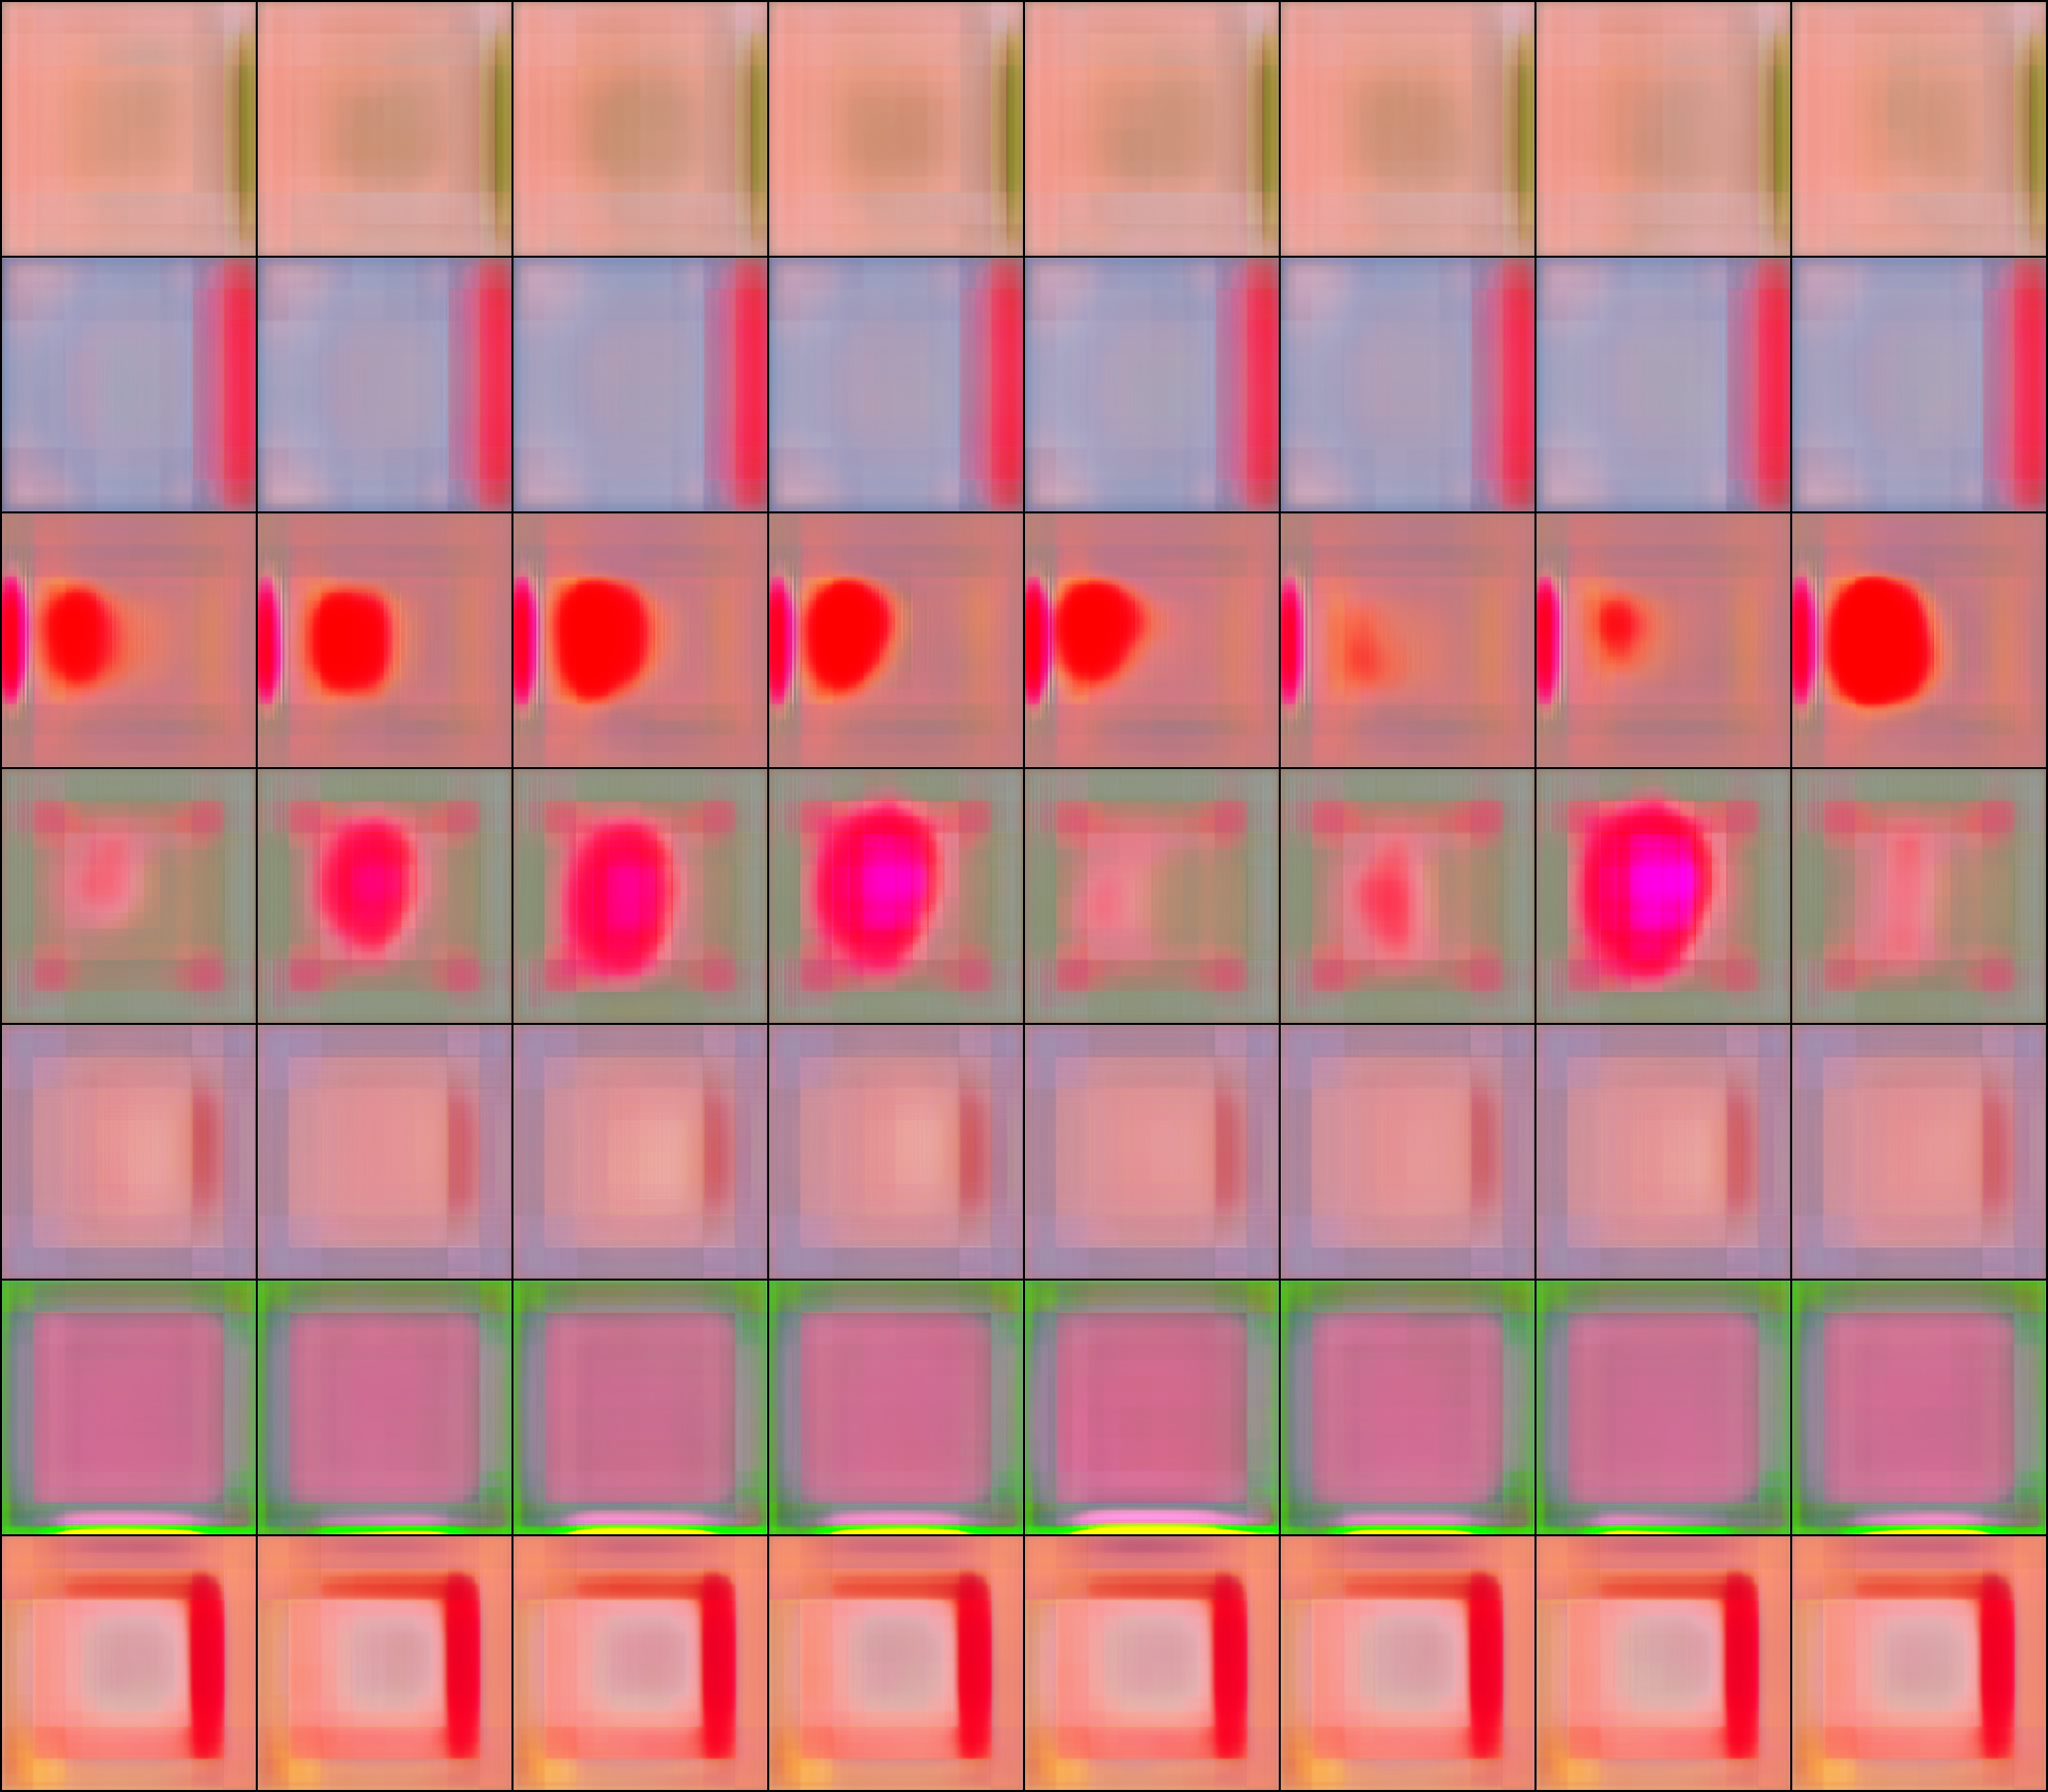


Thời gian phiên này: 9.83 giờ


In [17]:
import pandas as pd
from IPython.display import Image as IPImage, display

status()
gan_csv = RUNS / "gan_eval.csv"
if gan_csv.exists():
    print("\nChất lượng ảnh sinh (so với Table 2):")
    display(pd.read_csv(gan_csv).round(3))

rows = []
for name, *_ in EXPERIMENTS:
    f = RUNS / f"cls_{name}/metrics.json"
    if f.exists():
        m = json.load(open(f))
        for tta in ["no_TTA", "TTA"]:
            r = {k: round(100 * v, 2) for k, v in m[tta]["macro"].items()}
            rows.append({"model": name, "TTA": tta == "TTA", **r,
                         "top1_acc": round(100 * m[tta]["multiclass_accuracy"], 2)})
if rows:
    print("\nKết quả phân loại, macro average (so với Table 3):")
    display(pd.DataFrame(rows))

for p in [RUNS / "synth_preview.png", RUNS / "cls_tresnet50_stgan/confusion_TTA.png"]:
    if p.exists():
        print(p.name); display(IPImage(filename=str(p), width=600))

print(f"\nThời gian phiên này: {(time.time() - T0) / 3600:.2f} giờ")